In [ ]:
# AI-use disclosure (MSBI 555 requires this at the top of the notebook or in the README)
# The code in this repository (src/covidphylo, scripts/, notebooks/) was drafted with Claude (Anthropic).
# I ran it, checked the results against simulated ground truth and the unit tests (pytest),
# and am responsible for everything submitted.


# Project B - Reconstructing (and dating) SARS-CoV-2 phylogenetic trees

Shares `src/covidphylo` with Project A. This notebook adds the **interpretive layer**: best-fit rooting,
root-to-tip temporal signal, clock rate, node dating and lineage annotation.

Set `MODE = "sim"` (known rate/tMRCA - validates the code) or `"real"` (needs `data/` from `scripts/fetch_data.sh`).

In [7]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():            # allow running from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [8]:
MODE   = "sim"
METHOD = "nj_jc"                  # or "fasttree" / "iqtree" / "raxmlng" when installed
N_TIPS = 300                      # sim size; real: --max-tips in scripts/reconstruct.py
SEED   = 1
OUT = ROOT / "results" / "reconstruct_notebook"
OUT.mkdir(parents=True, exist_ok=True)

from covidphylo import clock, qc, metrics
from covidphylo.infer import available_methods
from covidphylo.reconstruct import run_reconstruction
print("methods available:", available_methods())

methods available: ['nj_jc', 'nj_p', 'upgma_jc']


## 1. Load data

In [10]:
if MODE == "sim":
    from covidphylo.simulate import simulate_dataset
    sim = simulate_dataset(N_TIPS, rate=1e-3, seed=SEED)
    aln, dates, lineages, sites = sim.aln, sim.tip_dates, sim.lineages, None
    print(f"true rate 1e-3 subs/site/yr, true tMRCA {sim.root_date:.3f}")
else:
    from covidphylo.seqio import Alignment
    meta = qc.read_metadata(ROOT / "data" / "metadata.tsv")
    meta["dec"] = meta["date"].map(clock.date_to_decimal_year)
    meta = meta[np.isfinite(meta["dec"])]
    sub = qc.subsample_stratified(meta, 1000, seed=SEED)
    aln = Alignment.from_fasta(ROOT / "data" / "aligned.fasta", keep=set(sub["name"]))
    dates, lineages = dict(zip(sub["name"], sub["dec"])), dict(zip(sub["name"], sub["lineage"]))
    vcf = ROOT / "data" / "problematic_sites_sarsCov2.vcf"
    sites = qc.build_mask(aln.length, qc.read_problematic_sites_vcf(vcf) if vcf.exists() else None)
aln.n, aln.length

true rate 1e-3 subs/site/yr, true tMRCA 2020.279


(300, 29903)

## 2. Run the pipeline (mask -> QC -> dedupe -> tree -> root -> clock -> figures)

In [12]:
log = run_reconstruction(aln, dates, lineages, OUT, method=METHOD, mask_sites=sites, seed=SEED,
                         n_perm=500, n_boot=300, verbose=False)
pd.Series({k: (np.round(v, 5) if isinstance(v, float) else v) for k, v in log.items()})

n_input                                                                   300
alignment_length                                                        29903
method                                                                  nj_jc
n_after_ambig_filter                                                      300
n_with_complete_date                                                      300
n_unique_sequences                                                        296
inference_wall_s                                                         0.35
clock_rate                                                            0.00099
clock_rate_ci95                (0.0009228481377786202, 0.0010436521334418576)
tmrca                                                              2020.38636
tmrca_ci95                           (2020.2971008223058, 2020.4578651731454)
r2                                                                    0.68698
p_permutation                                                   

## 3. Temporal signal
A clock-like signal needs a positive slope, decent R^2 and a permutation p-value well below 0.05.
(`p_permutation` here keeps the root fixed; say so in the methods section.)

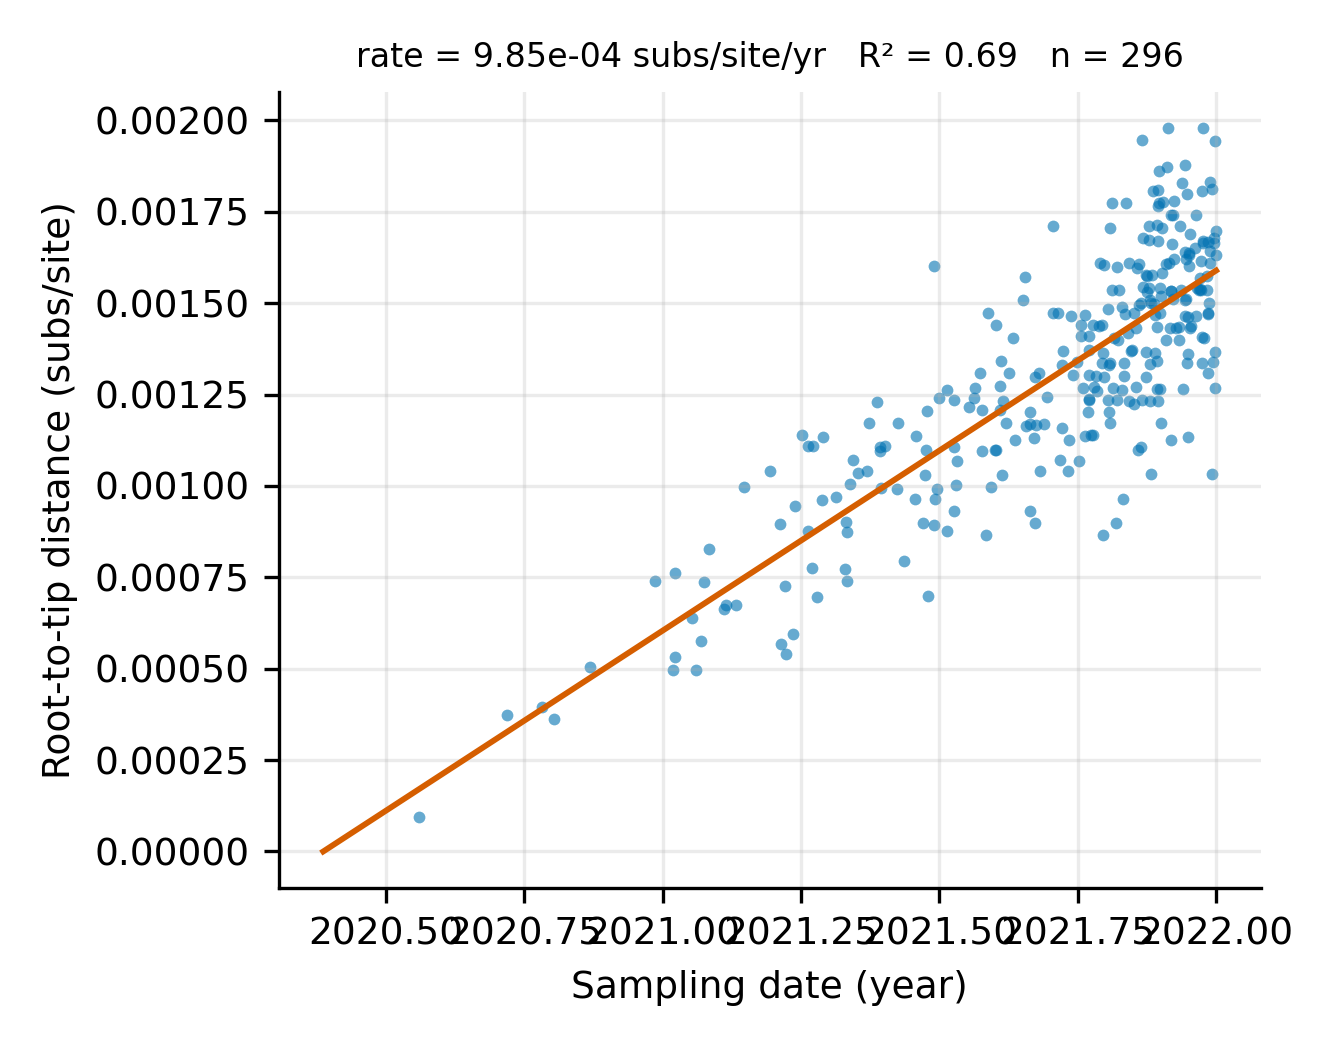

In [14]:
display(Image(str(OUT / "fig_root_to_tip.png")))

## 4. Dated tree coloured by lineage

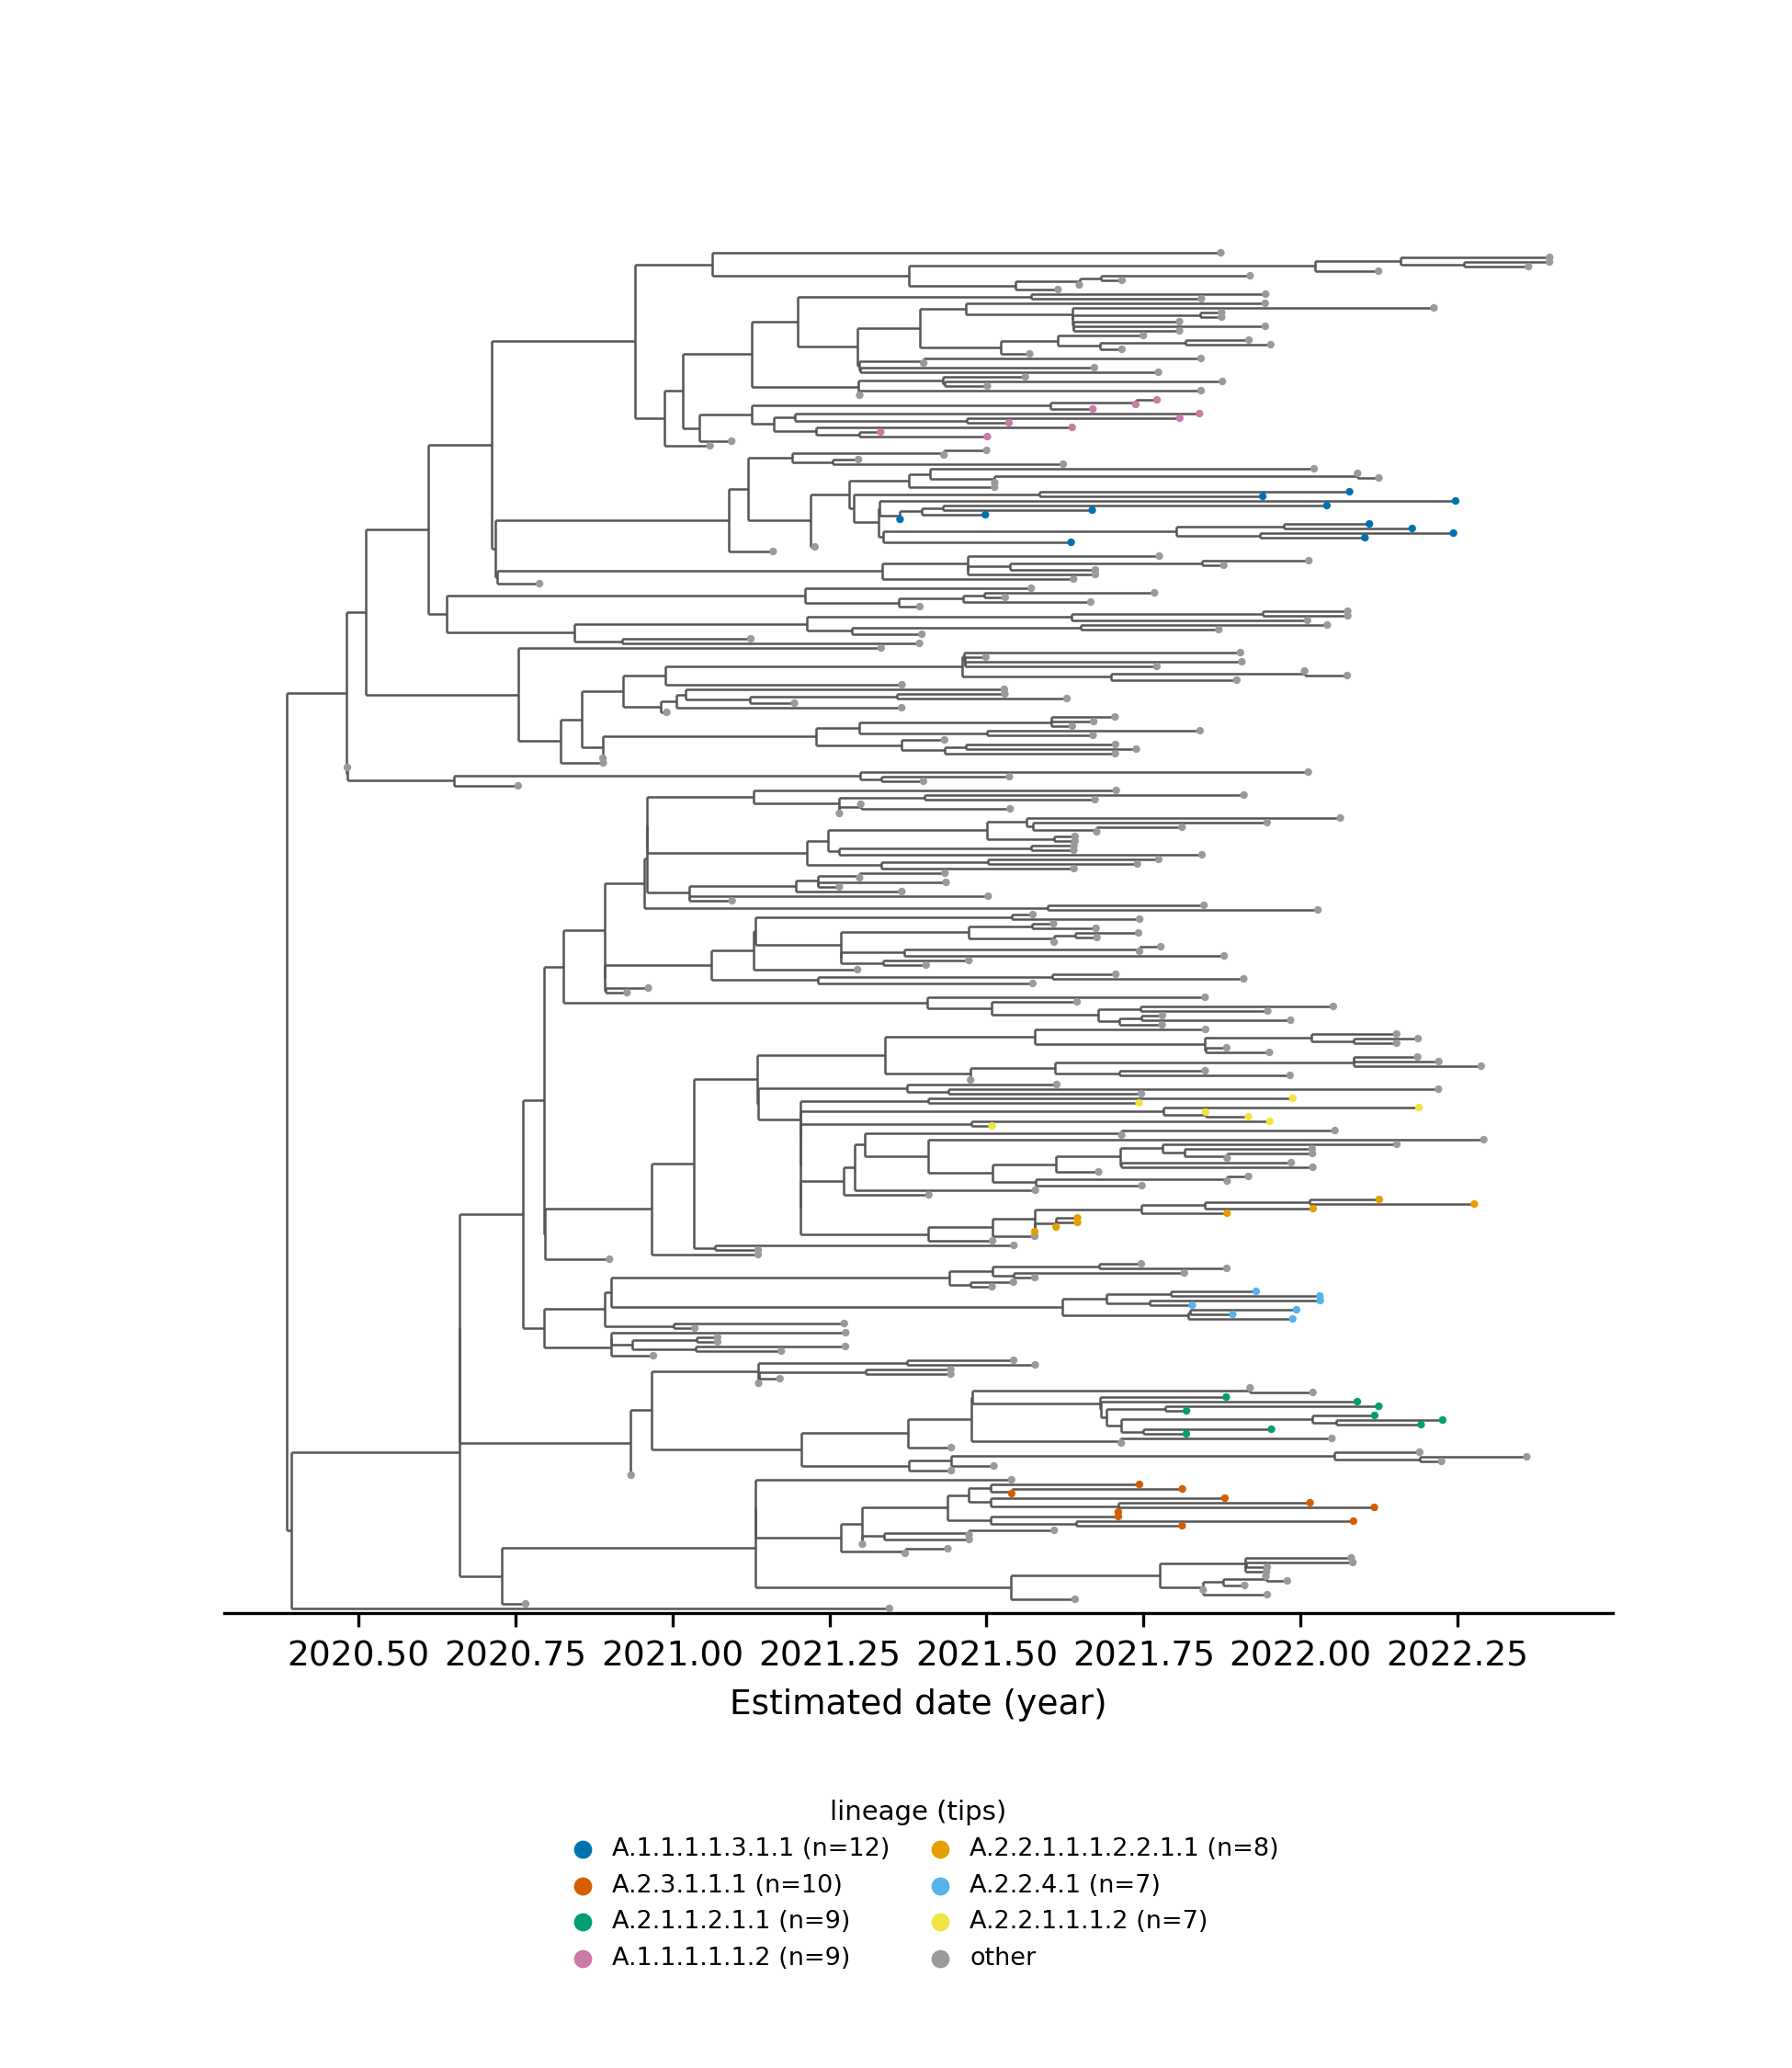

In [16]:
display(Image(str(OUT / "fig_dated_tree.png")))

## 5. Lineage summary and (sim only) comparison with the truth

In [18]:
display(pd.read_csv(OUT / "lineage_summary.csv").head(10))
if MODE == "sim":
    est = log["clock_rate"]; lo, hi = log["clock_rate_ci95"]
    print(f"rate: estimated {est:.2e} (95% CI {lo:.2e}-{hi:.2e}) vs true 1.00e-03")
    print(f"tMRCA: estimated {log['tmrca']:.2f} (95% CI {log['tmrca_ci95'][0]:.2f}-{log['tmrca_ci95'][1]:.2f}) vs true {sim.root_date:.2f}")

,lineage,n_tips,first_date,last_date
0,A.1.1.1.1.3.1.1,12,2021.287300,2022.000000
1,A.2.3.1.1.1,10,2021.633528,2021.977582
2,A.2.1.1.2.1.1,9,2021.755627,2021.996252
3,A.1.1.1.1.1.2,9,2021.525422,2021.894320
4,A.2.2.1.1.1.2.2.1.1,8,2021.424389,2021.914410
5,A.2.2.1.1.1.2,7,2021.392870,2021.878222
6,A.2.2.4.1,7,2021.805232,2021.945380
7,A.1.1.2.1.2.2.1,7,2021.577672,2021.920804
8,A.2.2.1.1.1.2.1.1.1.1.1,6,2021.713514,2021.983883
9,A.2.1.2,6,2021.330225,2021.808050


rate: estimated 9.85e-04 (95% CI 9.23e-04-1.04e-03) vs true 1.00e-03
tMRCA: estimated 2020.39 (95% CI 2020.30-2020.46) vs true 2020.28


## 6. Optional: compare tree-building methods on the same data
Because the core is shared with Project A, any method in `available_methods()` can be dropped in via `METHOD`.
For publication-quality dating use TreeTime/BEAST on the rooted tree written to `tree_rooted.nwk`.